# 3D Transport Data Plotting

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
import pytweezer.data_manager as DataManager
import pytweezer.analysis as an
import pytweezer.phasemask as pm
from scipy.optimize import curve_fit
import time

# ==============================================================================
# 1. GLOBAL PUBLICATION STYLE SETTINGS (rcParams) - SERIF VERSION
# ==============================================================================
plt.rcParams.update({
    "text.usetex": False,              # Set to True if you have a full LaTeX distribution installed
    "font.family": "serif",            # Changed to serif
    "font.serif": ["Times New Roman", "DejaVu Serif"], # Primary and fallback serif fonts
    "mathtext.fontset": "cm",          # Renders math symbols in LaTeX's Computer Modern font
    "font.size": 9,                    
    "axes.linewidth": 1.0,             
    "axes.labelsize": 10,
    "xtick.direction": "in",           
    "ytick.direction": "in",
    "xtick.major.size": 2,             
    "ytick.major.size": 2,
    "xtick.minor.size": 1,             
    "ytick.minor.size": 1,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.top": False,                 
    "ytick.right": False,
    "legend.frameon": False,           
    "legend.fontsize": 9,
    "figure.figsize": (3.37*1.5, 2.8*1.5),     # Standard APS single column
    "figure.dpi": 300,
    "savefig.bbox": "tight"            
})

dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(40+dx, -8+dy),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

gauss2d = lambda x, y, A, x0, y0, sx, sy, offset: (A * np.exp(-(((x - x0) ** 2) / (2 * sx ** 2) + ((y - y0) ** 2) / (2 * sy ** 2)))) + offset
A, x0, y0, sx, sy, offset = [-2.14197604e+03, -1.11443850e+01 - dx, 2.09919600e+00 - dy, 2.95002910e+03, 2.64281503e+03, 2.14239505e+03]

def wilson(k, n, z=1.0):                      # z = 1 (68.27%), 1.96 (95%)
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n))/d
    h = z/d*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return h

def extract_survival_probability(imgs1, imgs2, grid_positions1, grid_positions2, threshold='auto', window_size=5):
    if threshold == 'auto':
        pr_1, eta_1, thresh_1, fidelity_1 = an.get_array_loading_statistics(imgs1, grid_positions1, threshold_detection=True, window_size=window_size, binning=60, show_histogram=False, verbose=False)
        pr_2, eta_2, thresh_2, fidelity_2 = an.get_array_loading_statistics(imgs2, grid_positions2, threshold_detection=True, window_size=window_size, binning=60, show_histogram=False, verbose=False)
    else:
        pr_1, eta_1, thresh_1, fidelity_1 = an.get_array_loading_statistics(imgs1, grid_positions1, threshold_detection=False, threshold=threshold, window_size=window_size, binning=60, show_histogram=False, verbose=False)
        pr_2, eta_2, thresh_2, fidelity_2 = an.get_array_loading_statistics(imgs2, grid_positions2, threshold_detection=False, threshold=threshold, window_size=window_size, binning=60, show_histogram=False, verbose=False)
    survival_fractions = []
    for i in range(pr_1.shape[0]):

        pr_mat_1 = pr_1[i]
        pr_mat_2 = pr_2[i]

        pr_mat_1_binary = (pr_mat_1 > thresh_1).astype(int)
        pr_mat_2_binary = (pr_mat_2 > thresh_2).astype(int)
        survival_matrix = pr_mat_1_binary * pr_mat_2_binary

        init_occupation = pr_mat_1_binary.sum()
        final_occupation = pr_mat_2_binary.sum()
        survival_count = survival_matrix.sum()
        survival_fraction = survival_count / init_occupation if init_occupation > 0 else 0
        survival_fractions.append(survival_fraction)

    survival_probability = np.mean(survival_fractions)
    
    N_samples = pr_1.flatten().shape[0]
    survival_probability_err = wilson(survival_probability*N_samples, N_samples)
    return survival_probability, survival_probability_err

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


In [39]:
np.pi * 0.995**2 / 0.852

3.650534350786661

---
## Alternating Traps Out of Focus
### dz = 0.0 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

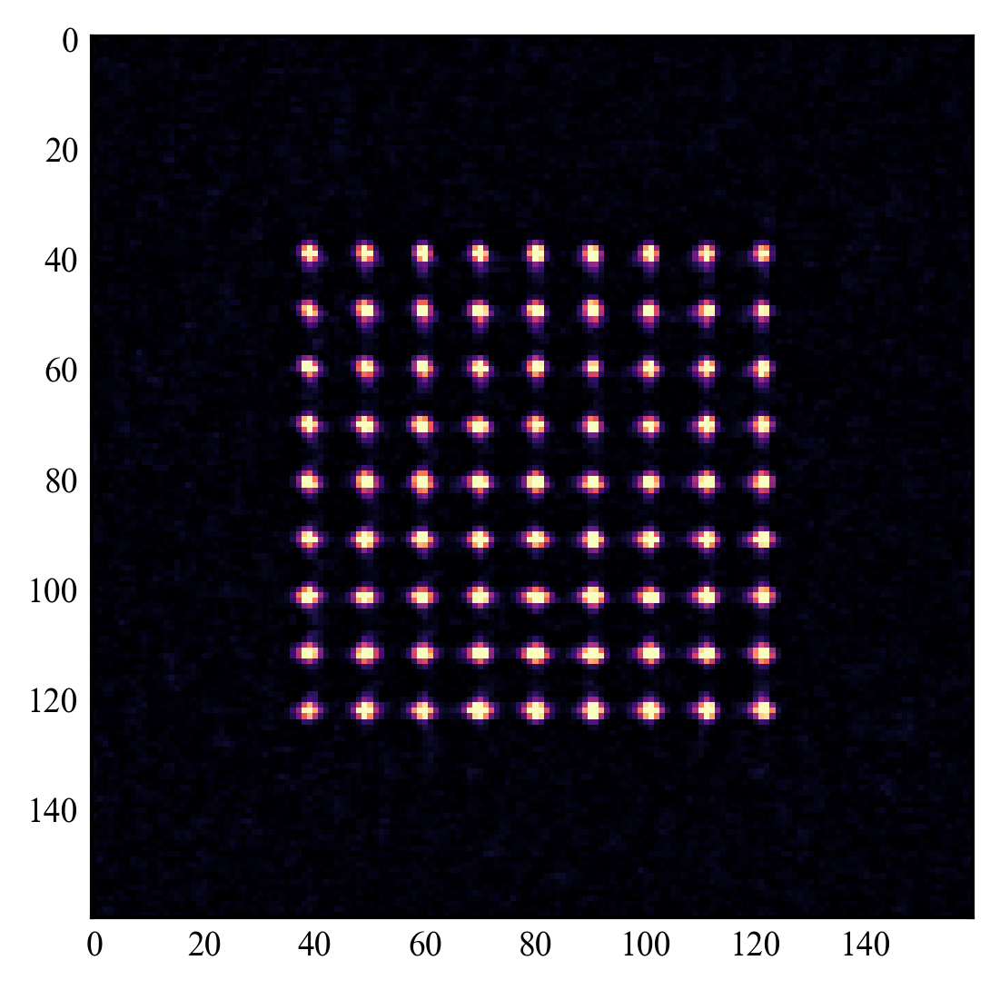

In [6]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_exp_2_5um_dz_transport")
imgs3 = dataset.pickles.get('imgs2.pkl')
feature_size = 5
imgs_n_mean = imgs3.mean(axis=0)
imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs_n_mean, feature_size=feature_size)

h, w = imgs_n_mean_filtered.shape
window = 80
dx, dy = 0, -4
imgs_cropped = imgs_n_mean_filtered[h//2-window-dx:h//2+window-dx, w//2-window-dy:w//2+window-dy]

plt.imshow(imgs_cropped, cmap='magma', vmax=imgs_cropped.max()*0.4)
img_defoc_0 = imgs_cropped

### dz = 5.0 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

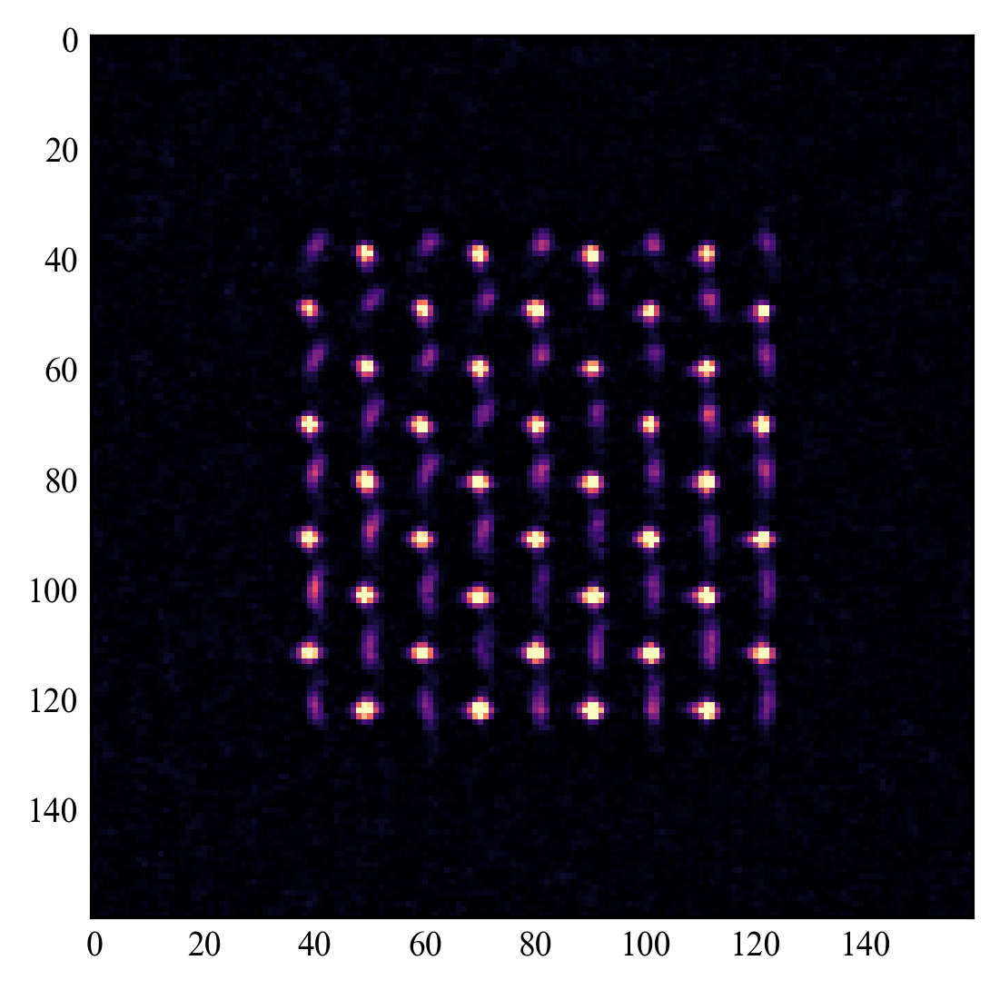

In [7]:

date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_exp_2_5um_dz_transport")
imgs3 = dataset.pickles.get('imgs3.pkl')
feature_size = 5
imgs_n_mean = imgs3.mean(axis=0)
imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs_n_mean, feature_size=feature_size)

h, w = imgs_n_mean_filtered.shape
window = 80
dx, dy = 0, -4
imgs_cropped = imgs_n_mean_filtered[h//2-window-dx:h//2+window-dx, w//2-window-dy:w//2+window-dy]

plt.imshow(imgs_cropped, cmap='magma', vmax=imgs_cropped.max()*0.4)
img_defoc_5 = imgs_cropped


### dz = 10.0 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

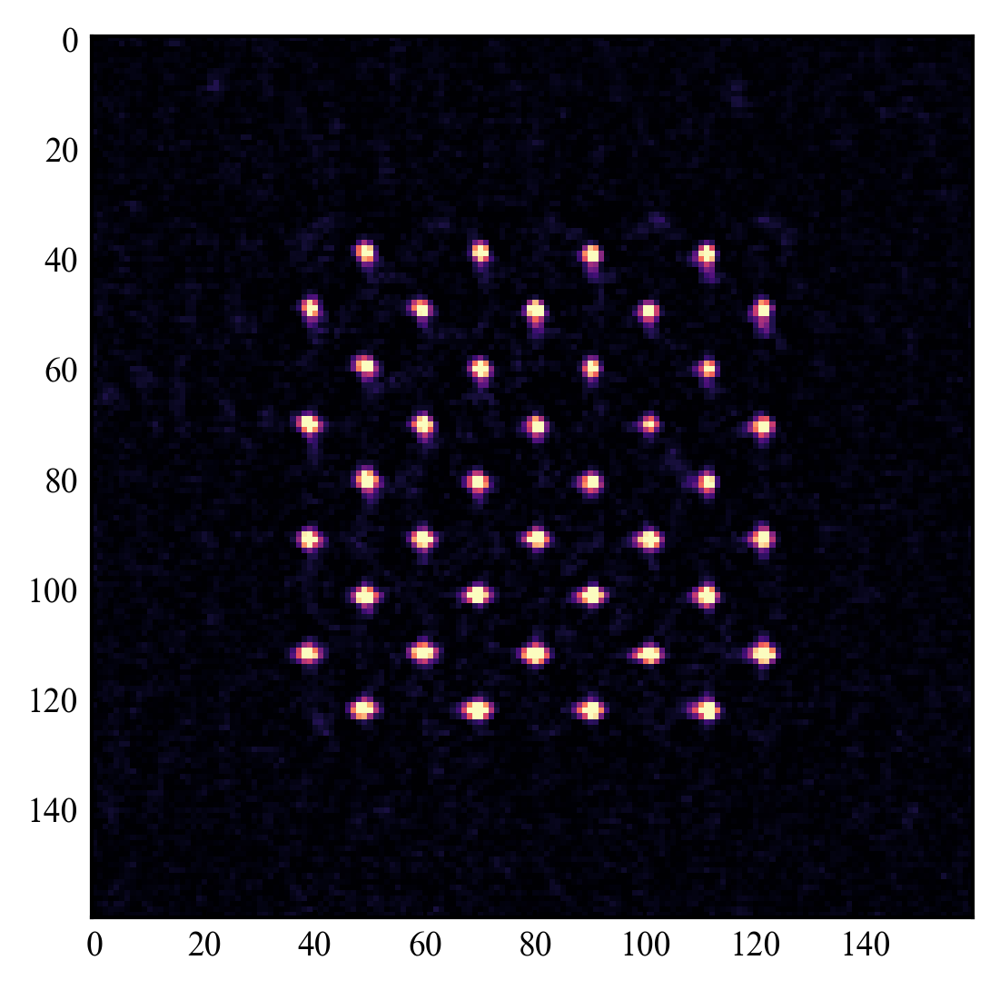

In [8]:

date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_exp_2_10um_dz_transport")
imgs3 = dataset.pickles.get('imgs3.pkl')
feature_size = 5
imgs_n_mean = imgs3.mean(axis=0)
imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs_n_mean, feature_size=feature_size)

h, w = imgs_n_mean_filtered.shape
window = 80
dx, dy = 0, -4
imgs_cropped = imgs_n_mean_filtered[h//2-window-dx:h//2+window-dx, w//2-window-dy:w//2+window-dy]

plt.imshow(imgs_cropped, cmap='magma', vmax=imgs_cropped.max()*0.4)
img_defoc_10 = imgs_cropped

---
## Axial Step Size Scan
### 0 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Looking for trap sites...
81 Atoms Detected.
Parameter 'x_centre' set to 131.4814814814815.
Parameter 'y_centre' set to 128.5185185185185.
Parameters saved.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 98.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 100.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 94.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 100.00 %
Trap (9) Loading Probability : 98.00 %
Trap (10) Loading Probability : 93.00 %
Trap (11) Loading Probability : 94.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 99.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 99.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 97.00 %

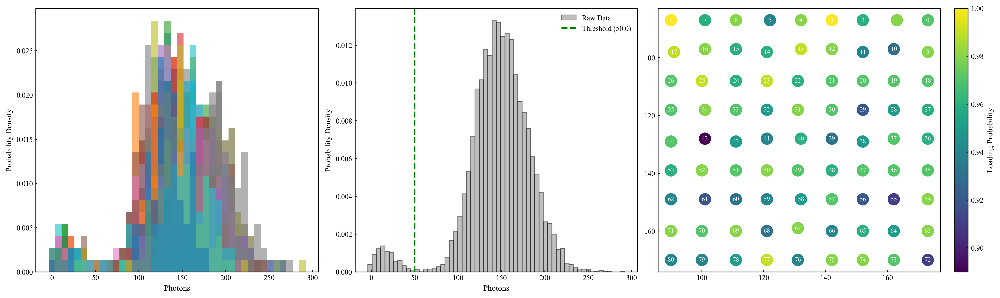

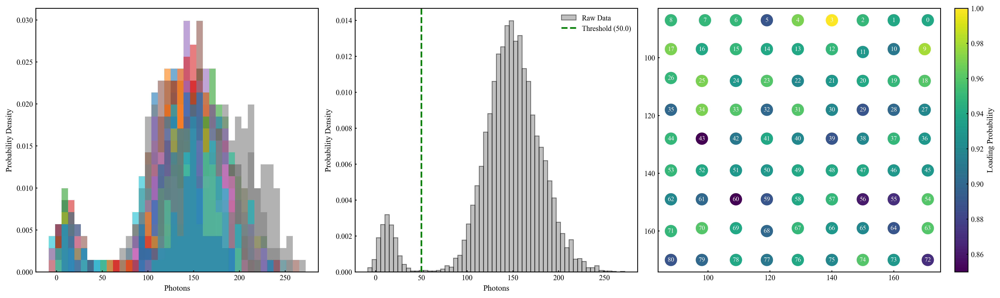

In [9]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_0um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
an.set_array_centre(grid_positions_2)
grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
an.set_array_centre(grid_positions_3)
grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv0, surv0_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv0:.4f} ± {surv0_err:.4f}")

### 1 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Looking for trap sites...
81 Atoms Detected.
Parameter 'x_centre' set to 131.6172839506173.
Parameter 'y_centre' set to 128.53086419753086.
Parameters saved.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 97.00 %
Trap (3) Loading Probability : 99.00 %
Trap (4) Loading Probability : 93.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 95.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 99.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 95.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 98.00 %
Trap (16) Loading Probability : 93.00 %
Trap (17) Loading Probability : 99.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 98.00 %


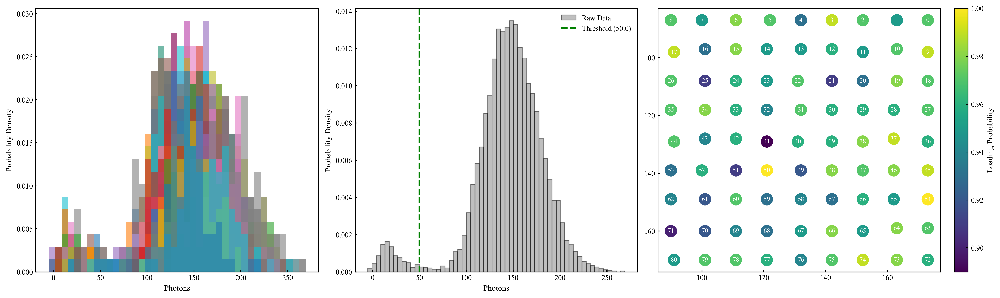

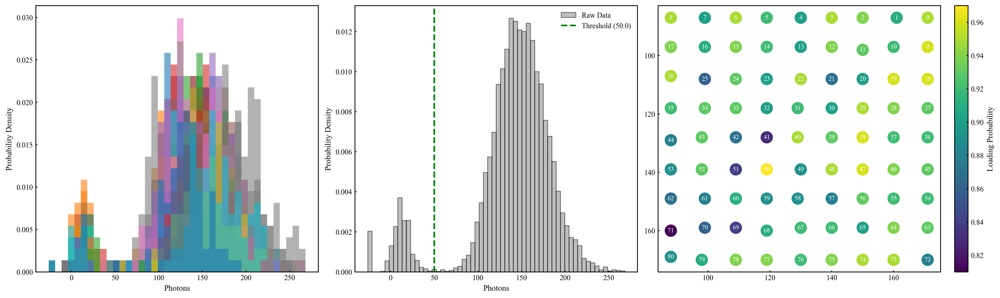

In [10]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_1um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
an.set_array_centre(grid_positions_2)
grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
an.set_array_centre(grid_positions_3)
grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv1, surv1_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv1:.4f} ± {surv1_err:.4f}")

### 2 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 98.00 %
Trap (2) Loading Probability : 97.00 %
Trap (3) Loading Probability : 98.00 %
Trap (4) Loading Probability : 97.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 95.00 %
Trap (8) Loading Probability : 100.00 %
Trap (9) Loading Probability : 95.00 %
Trap (10) Loading Probability : 96.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 99.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 99.00 %
Trap (15) Loading Probability : 97.00 %
Trap (16) Loading Probability : 97.00 %
Trap (17) Loading Probability : 98.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 99.00 %
Trap (21) Loading Probability : 93.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 98.00

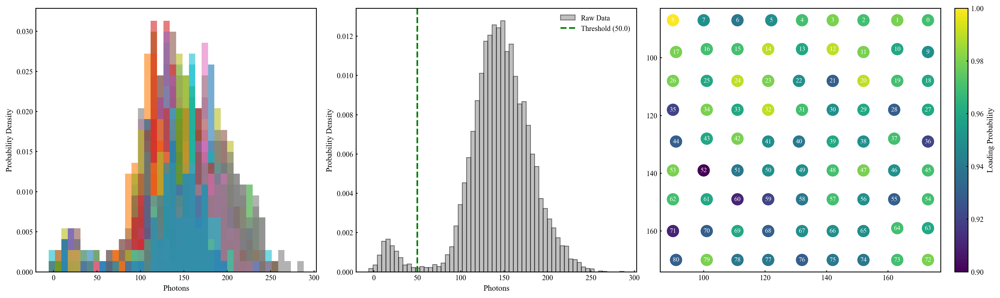

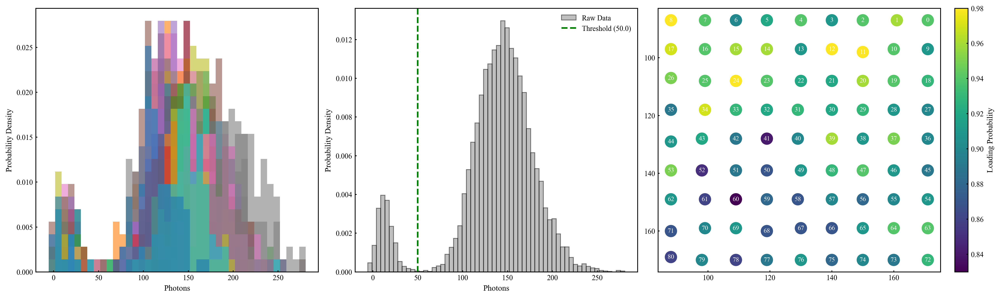

In [11]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_2um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv2, surv2_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv2:.4f} ± {surv2_err:.4f}")

### 3 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Trap (0) Loading Probability : 93.00 %
Trap (1) Loading Probability : 99.00 %
Trap (2) Loading Probability : 97.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 98.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 96.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 98.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 99.00 %
Trap (14) Loading Probability : 97.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 97.00 %
Trap (17) Loading Probability : 97.00 %
Trap (18) Loading Probability : 99.00 %
Trap (19) Loading Probability : 98.00 %
Trap (20) Loading Probability : 94.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 98.00 %
Trap (23) Loading Probability : 99.00 

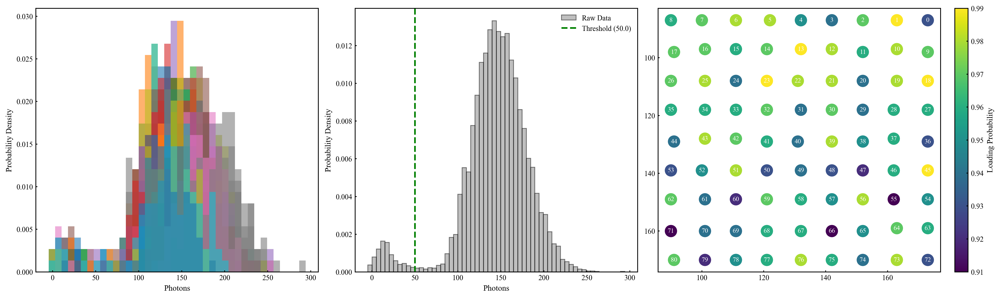

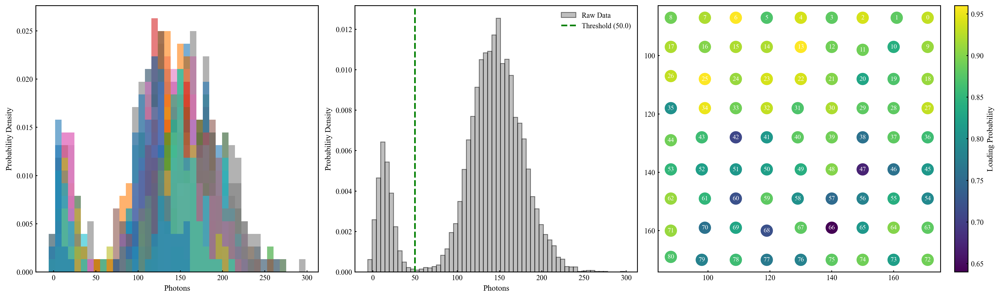

In [12]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_3um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv3, surv3_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv3:.4f} ± {surv3_err:.4f}")

### 4 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 99.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 99.00 %
Trap (6) Loading Probability : 99.00 %
Trap (7) Loading Probability : 98.00 %
Trap (8) Loading Probability : 99.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 96.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 98.00 %
Trap (14) Loading Probability : 99.00 %
Trap (15) Loading Probability : 97.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 97.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 95.00 %
Trap (21) Loading Probability : 97.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 95.00 

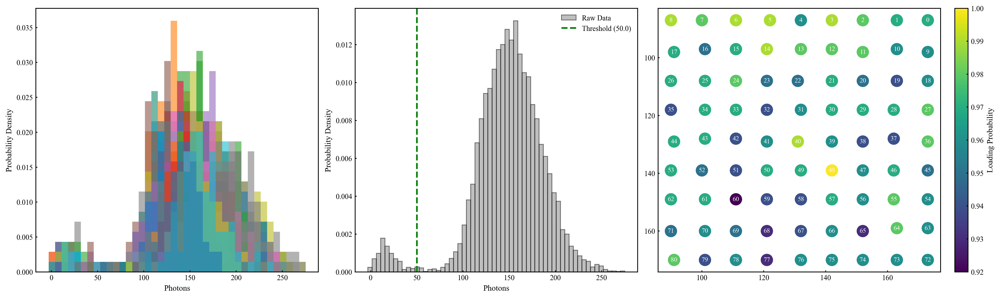

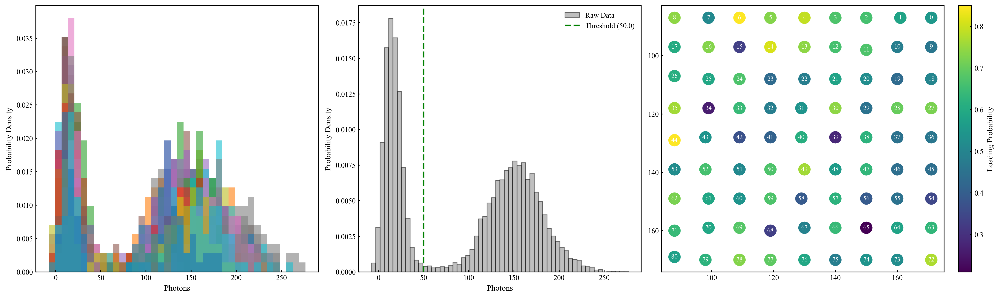

In [13]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_4um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv4, surv4_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv4:.4f} ± {surv4_err:.4f}")

### 5 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Trap (0) Loading Probability : 99.00 %
Trap (1) Loading Probability : 100.00 %
Trap (2) Loading Probability : 100.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 99.00 %
Trap (8) Loading Probability : 98.00 %
Trap (9) Loading Probability : 99.00 %
Trap (10) Loading Probability : 99.00 %
Trap (11) Loading Probability : 93.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 97.00 %
Trap (16) Loading Probability : 100.00 %
Trap (17) Loading Probability : 98.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 95.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 96.00 %
Trap (23) Loading Probability : 95.

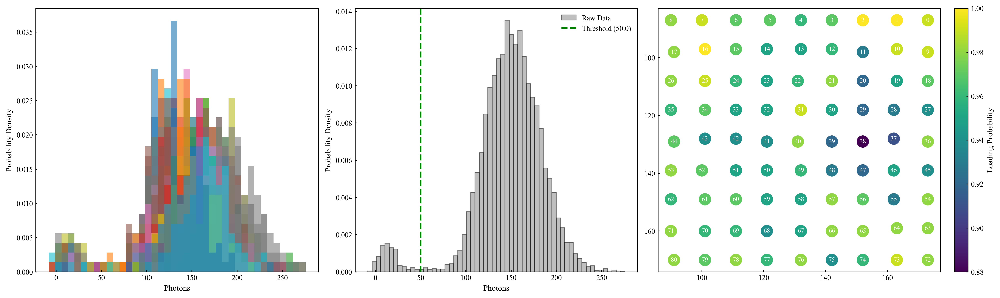

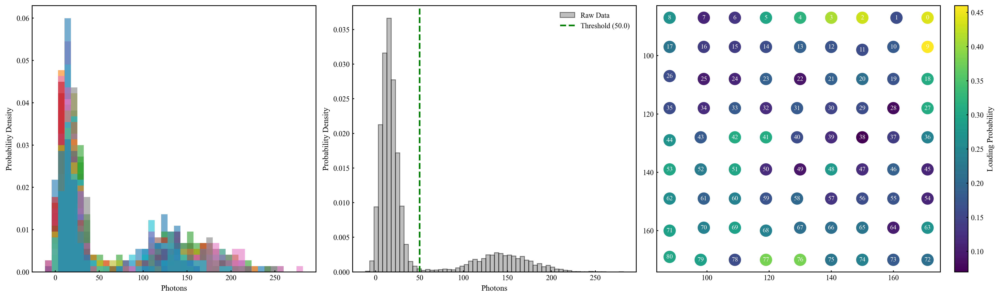

In [14]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_5um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv5, surv5_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv5:.4f} ± {surv5_err:.4f}")

### 6 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 96.00 %
Trap (2) Loading Probability : 99.00 %
Trap (3) Loading Probability : 96.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 98.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 96.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 95.00 %
Trap (11) Loading Probability : 97.00 %
Trap (12) Loading Probability : 94.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 91.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 97.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 95.00 %
Trap (20) Loading Probability : 86.00 %
Trap (21) Loading Probability : 94.00 %
Trap (22) Loading Probability : 98.00 %
Trap (23) Loading Probability : 92.00 

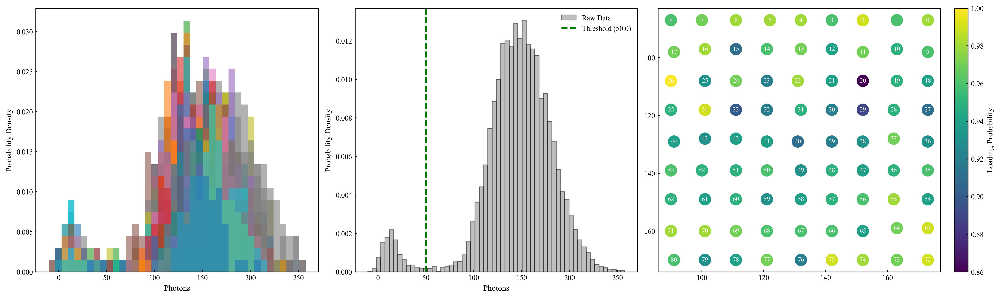

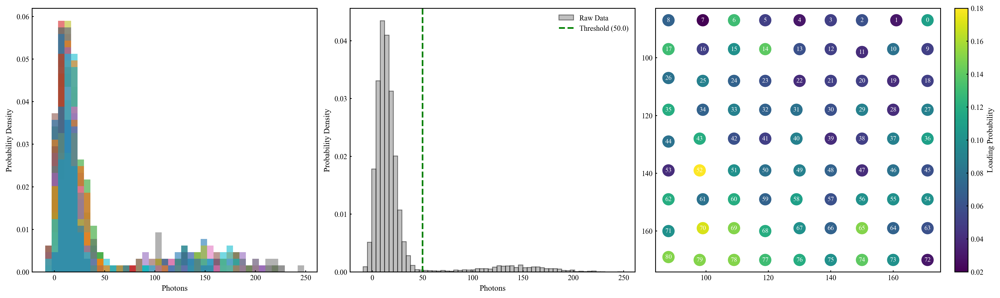

In [15]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_dz_6um_survival_probability")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
W2 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n2, y_n2, _ = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
W3 = np.ones((9,9))
spacing_um = 5.0
_, _, x_n3, y_n3, _ = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 9*9, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
surv6, surv6_err = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, grid_positions_2, grid_positions_3, threshold=50, window_size=5)
print(f"Survival probability: {surv6:.4f} ± {surv6_err:.4f}")


<ErrorbarContainer object of 3 artists>

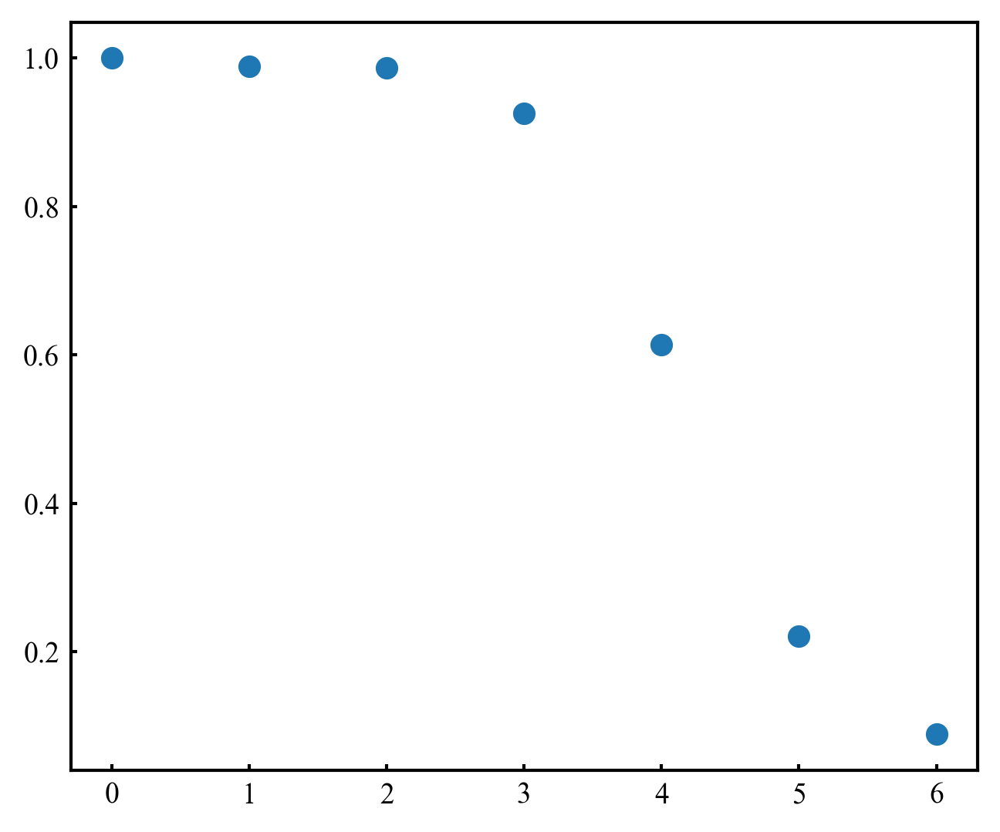

In [16]:
dz_step_scan = np.array([0, 1, 2, 3, 4, 5, 6])
survival_probabilities_axialstep = np.array([surv0, surv1, surv2, surv3, surv4, surv5, surv6])/surv0
survival_probabilities_err_axialstep = np.array([surv0_err, surv1_err, surv2_err, surv3_err, surv4_err, surv5_err, surv6_err])/surv0

plt.errorbar(dz_step_scan, survival_probabilities_axialstep, yerr=survival_probabilities_err_axialstep, fmt='o', capsize=3)

In [17]:
survival_probabilities_axialstep

array([1.        , 0.98846588, 0.98657186, 0.92593864, 0.61349179,
       0.22119106, 0.08915889])

In [18]:
survival_probabilities_err_axialstep

array([0.00202261, 0.00233474, 0.00238143, 0.00350034, 0.00563721,
       0.00470852, 0.00322364])

---

## Leap Frog Scan

In [19]:
W2a = np.ones((8,5))
spacing_um = 12.0

_, _, x_n2_a, y_n2_a, _ = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
y_n2_a *= 0.5

_, _, x_n2_b, y_n2_b, _ = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
y_n2_b *= 0.5
x_n2_b += 5.0

x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)
W3a = np.ones((8,5))
spacing_um = 12.0

_, _, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
y_n3_a *= 0.5

_, _, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
y_n3_b *= 0.5
x_n3_b -= 5.0

x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um


### dz = 35 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

Looking for trap sites...
80 Atoms Detected.
Parameter 'x_centre' set to 126.2625.
Parameter 'y_centre' set to 128.4875.
Parameters saved.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 94.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 95.00 %
Trap (8) Loading Probability : 94.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 93.00 %
Trap (11) Loading Probability : 95.00 %
Trap (12) Loading Probability : 93.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 93.00 %
Trap (18) Loading Probability : 91.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability :

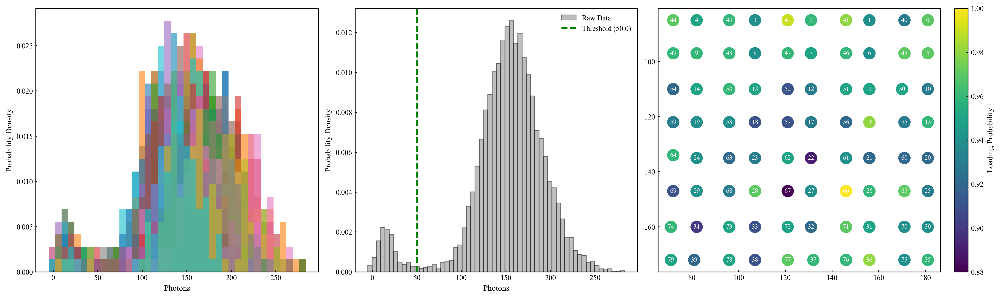

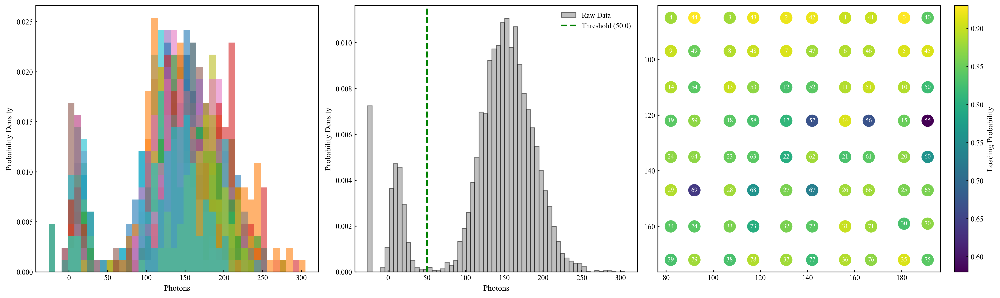

In [20]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_leapfrog_35um_1dz_step")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=200)
an.set_array_centre(grid_positions_2)
grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 80, detection_step=200)
an.set_array_centre(grid_positions_3)
grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
# Moving site indexes are numbered 40 to 79, static sites are numbered 0 to 39. Split grid_positions_2 and grid_positions_3, which are dictionaries with indices as keys and values as the site positions, into moving and static sites based on these indexes. 

moving_sites_2 = {k-40: v for k, v in grid_positions_2.items() if 40 <= k < 80}
static_sites_2 = {k: v for k, v in grid_positions_2.items() if 0 <= k < 40}

moving_sites_3 = {k-40: v for k, v in grid_positions_3.items() if 40 <= k < 80}
static_sites_3 = {k: v for k, v in grid_positions_3.items() if 0 <= k < 40}

surv35_static, surv35_err_static = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, static_sites_2, static_sites_3, threshold=50, window_size=5)
surv35_moving, surv35_err_moving = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, moving_sites_2, moving_sites_3, threshold=50, window_size=5)

print(f"Survival probability: {surv35_moving:.4f} ± {surv35_err_moving:.4f}")
print(f"Survival probability: {surv35_static:.4f} ± {surv35_err_static:.4f}")

### dz = 25 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

Looking for trap sites...
80 Atoms Detected.
Parameter 'x_centre' set to 126.325.
Parameter 'y_centre' set to 128.05.
Parameters saved.
Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 96.00 %
Trap (2) Loading Probability : 97.00 %
Trap (3) Loading Probability : 100.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 98.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 94.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 99.00 %
Trap (10) Loading Probability : 95.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 95.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 95.00 %
Trap (18) Loading Probability : 98.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 98.00 %
Trap (21) Loading Probability : 9

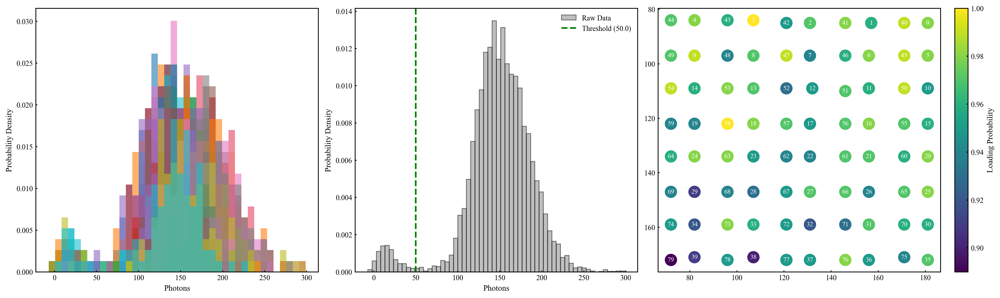

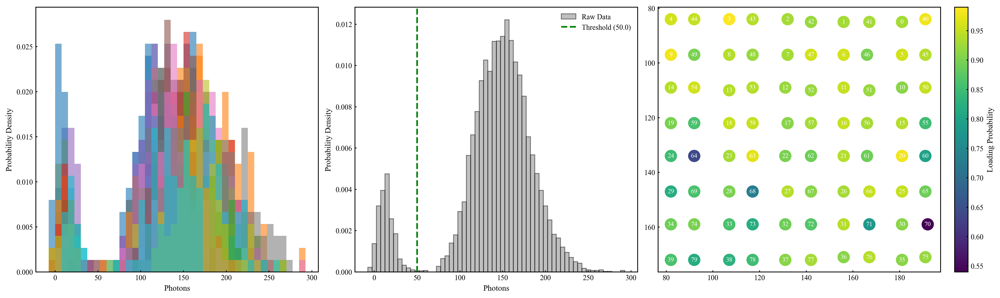

In [21]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_leapfrog_25um_1dz_step_1")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=200)
an.set_array_centre(grid_positions_2)
grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 80, detection_step=200)
an.set_array_centre(grid_positions_3)
grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
# Moving site indexes are numbered 40 to 79, static sites are numbered 0 to 39. Split grid_positions_2 and grid_positions_3, which are dictionaries with indices as keys and values as the site positions, into moving and static sites based on these indexes. 

moving_sites_2 = {k-40: v for k, v in grid_positions_2.items() if 40 <= k < 80}
static_sites_2 = {k: v for k, v in grid_positions_2.items() if 0 <= k < 40}

moving_sites_3 = {k-40: v for k, v in grid_positions_3.items() if 40 <= k < 80}
static_sites_3 = {k: v for k, v in grid_positions_3.items() if 0 <= k < 40}

surv25_static, surv25_err_static = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, static_sites_2, static_sites_3, threshold=50, window_size=5)
surv25_moving, surv25_err_moving = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, moving_sites_2, moving_sites_3, threshold=50, window_size=5)

print(f"Survival probability: {surv25_moving:.4f} ± {surv25_err_moving:.4f}")
print(f"Survival probability: {surv25_static:.4f} ± {surv25_err_static:.4f}")

### dz = 15 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

Trap (0) Loading Probability : 92.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 99.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 92.00 %
Trap (5) Loading Probability : 94.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 95.00 %
Trap (9) Loading Probability : 94.00 %
Trap (10) Loading Probability : 92.00 %
Trap (11) Loading Probability : 91.00 %
Trap (12) Loading Probability : 94.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 87.00 %
Trap (16) Loading Probability : 91.00 %
Trap (17) Loading Probability : 94.00 %
Trap (18) Loading Probability : 91.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 95.00 %
Trap (22) Loading Probability : 92.00 %
Trap (23) Loading Probability : 93.00 %
Trap (24) Loading Probability : 95.00 %
Trap (25) 

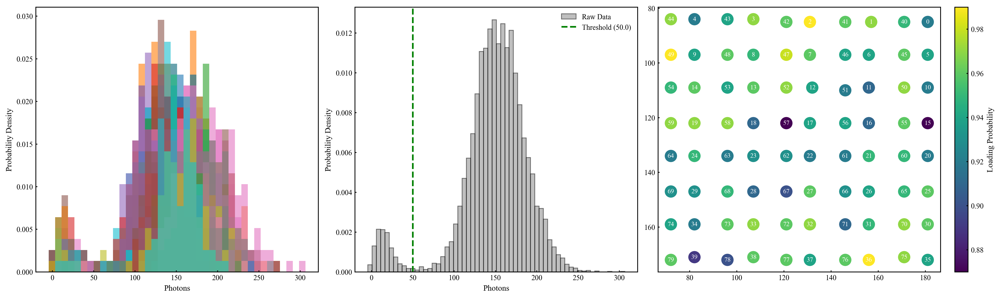

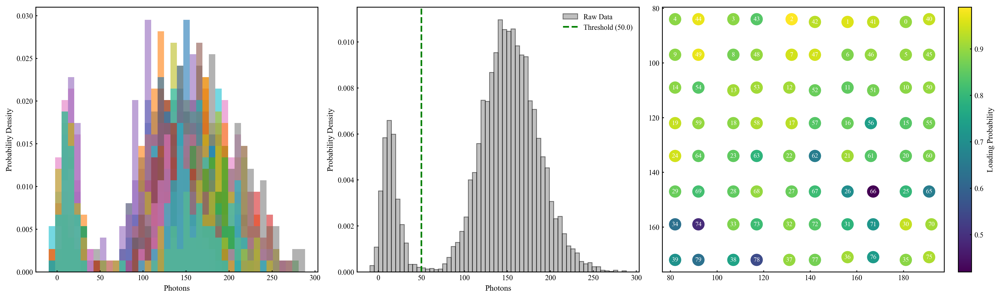

In [22]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_leapfrog_15um_1dz_step")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 80, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
# Moving site indexes are numbered 40 to 79, static sites are numbered 0 to 39. Split grid_positions_2 and grid_positions_3, which are dictionaries with indices as keys and values as the site positions, into moving and static sites based on these indexes. 

moving_sites_2 = {k-40: v for k, v in grid_positions_2.items() if 40 <= k < 80}
static_sites_2 = {k: v for k, v in grid_positions_2.items() if 0 <= k < 40}

moving_sites_3 = {k-40: v for k, v in grid_positions_3.items() if 40 <= k < 80}
static_sites_3 = {k: v for k, v in grid_positions_3.items() if 0 <= k < 40}

surv15_static, surv15_err_static = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, static_sites_2, static_sites_3, threshold=50, window_size=5)
surv15_moving, surv15_err_moving = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, moving_sites_2, moving_sites_3, threshold=50, window_size=5)

print(f"Survival probability: {surv15_moving:.4f} ± {surv15_err_moving:.4f}")
print(f"Survival probability: {surv15_static:.4f} ± {surv15_err_static:.4f}")

### dz = 5 um

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 93.00 %
Trap (2) Loading Probability : 95.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 93.00 %
Trap (6) Loading Probability : 90.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 96.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 90.00 %
Trap (12) Loading Probability : 94.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 98.00 %
Trap (15) Loading Probability : 93.00 %
Trap (16) Loading Probability : 93.00 %
Trap (17) Loading Probability : 94.00 %
Trap (18) Loading Probability : 99.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 91.00 %
Trap (21) Loading Probability : 92.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 96.00 %
Trap (24) Loading Probability : 98.00 %
Trap (25) 

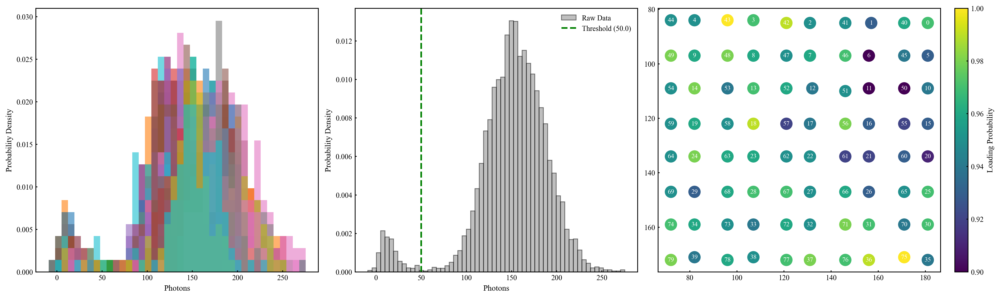

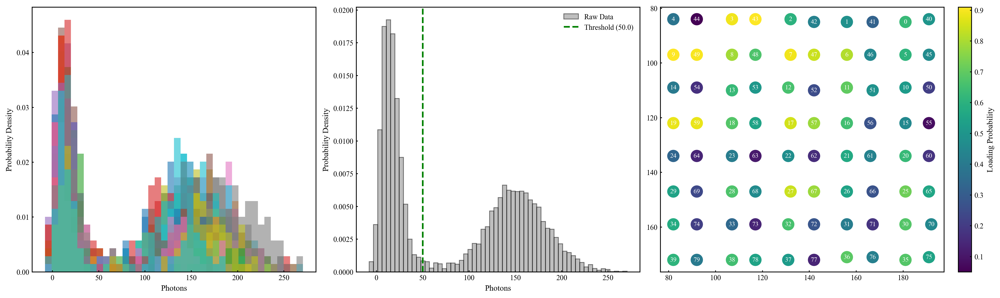

In [23]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_leapfrog_5um_1dz_step")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
imgs_2_mean = imgs2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=200)
#an.set_array_centre(grid_positions_2)
#grid_positions_2 = an.index_grid_positions(grid_positions_2, x_n2, y_n2)
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
imgs_3_mean = imgs3.mean(axis=0)
imgs_3_mean_filtered = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)
feature_size, window = 10, 5
#grid_positions_3, _ = an.detect_trap_sites(imgs_3_mean_filtered, 80, detection_step=200)
#an.set_array_centre(grid_positions_3)
#grid_positions_3 = an.index_grid_positions(grid_positions_3, x_n3, y_n3)
imgs_3_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs3]
photons3, loading_probabilities3, threshold3, fidelity3 = an.get_array_loading_statistics(imgs_3_filtered, grid_positions_3, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)
# Moving site indexes are numbered 40 to 79, static sites are numbered 0 to 39. Split grid_positions_2 and grid_positions_3, which are dictionaries with indices as keys and values as the site positions, into moving and static sites based on these indexes. 

moving_sites_2 = {k-40: v for k, v in grid_positions_2.items() if 40 <= k < 80}
static_sites_2 = {k: v for k, v in grid_positions_2.items() if 0 <= k < 40}

moving_sites_3 = {k-40: v for k, v in grid_positions_3.items() if 40 <= k < 80}
static_sites_3 = {k: v for k, v in grid_positions_3.items() if 0 <= k < 40}

surv5_static, surv5_err_static = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, static_sites_2, static_sites_3, threshold=50, window_size=5)
surv5_moving, surv5_err_moving = extract_survival_probability(imgs_2_filtered, imgs_3_filtered, moving_sites_2, moving_sites_3, threshold=50, window_size=5)

print(f"Survival probability: {surv5_moving:.4f} ± {surv5_err_moving:.4f}")
print(f"Survival probability: {surv5_static:.4f} ± {surv5_err_static:.4f}")

Text(0, 0.5, 'Transport Survival Probability')

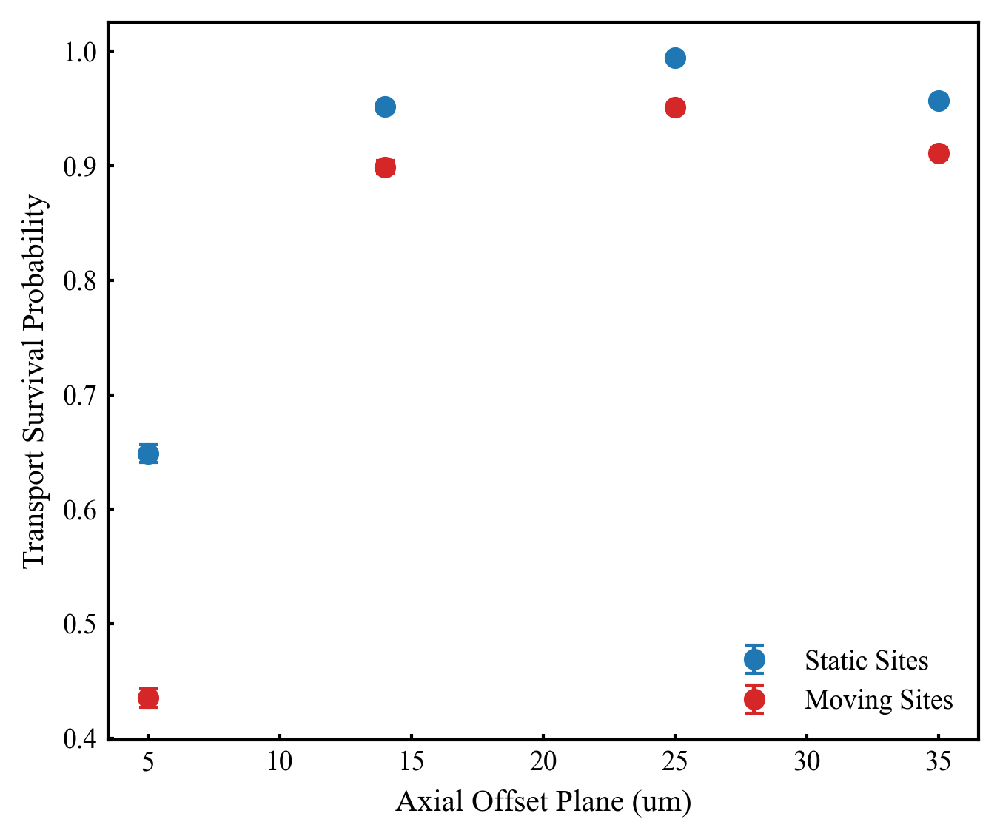

In [24]:
dz_leapfrog_scan = np.array([5, 14, 25, 35])

survival_probabilities_leapfrog_static = np.array([surv5_static, surv15_static, surv25_static, surv35_static])/surv0
survival_probabilities_err_leapfrog_static = np.array([surv5_err_static, surv15_err_static, surv25_err_static, surv35_err_static])/surv0

survival_probabilities_leapfrog_moving = np.array([surv5_moving, surv15_moving, surv25_moving, surv35_moving])/surv0
survival_probabilities_err_leapfrog_moving = np.array([surv5_err_moving, surv15_err_moving, surv25_err_moving, surv35_err_moving])/surv0

plt.errorbar(dz_leapfrog_scan, survival_probabilities_leapfrog_static, yerr=survival_probabilities_err_leapfrog_static, fmt='o', capsize=3, label="Static Sites", color='C0')
plt.errorbar(dz_leapfrog_scan, survival_probabilities_leapfrog_moving, yerr=survival_probabilities_err_leapfrog_moving, fmt='o', capsize=3, label="Moving Sites", color='C3')
plt.legend()

plt.xlabel("Axial Step Size (um)")
plt.xlabel("Axial Offset Plane (um)")
plt.ylabel("Transport Survival Probability")

In [28]:
print(f"Max. static survival = {survival_probabilities_leapfrog_static.max()} += {survival_probabilities_err_leapfrog_static[np.argmax(survival_probabilities_leapfrog_static)]}")
print(f"Max. moving survival = {survival_probabilities_leapfrog_moving.max()} += {survival_probabilities_err_leapfrog_moving[np.argmax(survival_probabilities_leapfrog_moving)]}")

Max. static survival = 0.9941870484980562 += 0.00311230881350209
Max. moving survival = 0.9510954616643074 += 0.004416817286951216


### Image

Datasets found in C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26:
  - Baseline_13x13_5um_initial/
  - Baseline_13x13_5um_initial_2/
  - Baseline_13x13_5um_initial_3/
  - Baseline_13x13_5um_survival_probability/
  - rearrange_transport_100ms_baseline_survival_probability/
  - rearrange_transport_13x13_to_90kagome_5um_spacing/
  - rearrange_transport_13x13_to_90kagome_5um_spacing_1/
  - rearrange_transport_dx_0_5um_survival_probability/
  - rearrange_transport_dx_0_5um_survival_probability_1/
  - rearrange_transport_dx_0um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability/
  - rearrange_transport_dx_1_5um_survival_probability_1/
  - rearrange_transport_dx_1um_survival_probability/
  - rearrange_transport_dx_1um_survival_probability_1/
  - rearrange_transport_dz_0um_survival_probability/
  - rearrange_transport_dz_1um_survival_probability/
  - rearrange_transport_dz_2um_survival_probability/
  - rearrange_transport_dz_3um_survival_probability

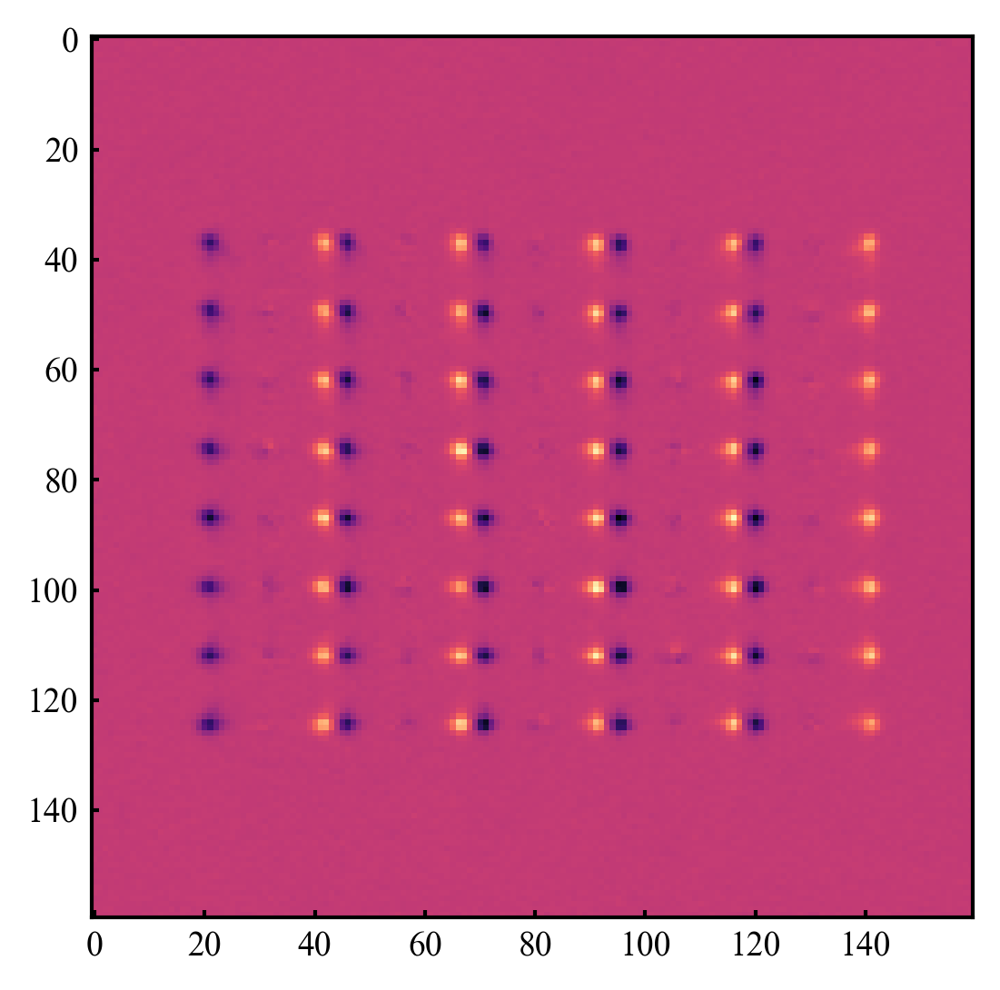

In [29]:
date = "13Oct26"
DataManager.list_datasets(date);
dataset = DataManager.load_dataset(date, "rearrange_transport_leapfrog_25um_1dz_step")
imgs2 = dataset.pickles.get('imgs2.pkl')
imgs3 = dataset.pickles.get('imgs3.pkl')
window = 80
dx, dy = int(0), int(-3)
imgs_2_mean = imgs2.mean(axis=0)
img_leapfrog_0 = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)[h//2-window-dx:h//2+window-dx, w//2-window-dy:w//2+window-dy]

plt.imshow(img_leapfrog_0, cmap='magma', vmax=img_leapfrog_0.max()*0.5)
imgs_3_mean = imgs3.mean(axis=0)
img_leapfrog_1 = an.morphological_tophat_high_pass(imgs_3_mean, feature_size=feature_size)[h//2-window-dx:h//2+window-dx, w//2-window-dy:w//2+window-dy]
plt.imshow(img_leapfrog_1, cmap='magma', vmax=img_leapfrog_1.max()*0.5)

plt.imshow(img_leapfrog_1 - img_leapfrog_0, cmap='magma')

# Combined Plot

In [36]:
"""
3D transport figure, 172 mm double column, eight square panels.

Row 1  (a)-(c) checkerboard sublattice displaced axially by 0, 5, 10 um (tweezer light)
       (d)     transport survival vs axial step size
Row 2  (e)     schematic of the leapfrog through the third dimension
       (f)-(g) averaged atom images before / after the leapfrog
       (h)     survival of stationary and displaced atoms vs lift height d

Usage, with your variables already in memory (e.g. in a notebook):

    from fig_3d_transport import make_figure
    make_figure(img_defoc_0, img_defoc_5, img_defoc_10,
                dz_step_scan, survival_probabilities_axialstep,
                survival_probabilities_err_axialstep,
                img_leapfrog_0, img_leapfrog_1,
                dz_leapfrog_scan,
                survival_probabilities_leapfrog_static,
                survival_probabilities_err_leapfrog_static,
                survival_probabilities_leapfrog_moving,
                survival_probabilities_err_leapfrog_moving,
                out="fig_3d_transport.pdf")

Run this file directly to see the layout with synthetic stand-in data.
"""
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch, Polygon, Ellipse
from scipy.stats import norm

MM = 1/25.4

BLUE, RED, GREY = "tab:blue", "C3", "tab:gray"
# Scale bars are calibrated from the known site spacing, separately for each row of images:
PITCH_AXIAL_UM = 5.0        # site spacing in panels (a)-(c)
PITCH_COLUMNS_UM = 5.0      # spacing between neighbouring columns in panels (f)-(g)
CMAP = "magma"


# =============================================================================
# Scale-bar calibration from the known site spacing
# =============================================================================
def pitch_from_image(img, rel_threshold=0.3, nbhd=5, win=4):
    """Site spacing in pixels from an image of a square array with all sites lit.
    Spots: local maxima, refined to the intensity-weighted centroid in a
    (2*win+1)^2 window. Pitch: spot coordinates are grouped into columns and rows, and
    the mean position of each column (row) is fitted against its index; the slope is
    the pitch. Fitting the whole lattice averages out per-spot centroid errors.
    Returns (pitch, spot positions (n, 2) as (y, x))."""
    from scipy.ndimage import maximum_filter
    img = np.asarray(img, float)
    bg = np.median(img)
    peaks = (img == maximum_filter(img, size=nbhd)) & (img > rel_threshold * img.max())
    yy, xx = np.mgrid[-win:win + 1, -win:win + 1]
    pts = []
    for py, px in zip(*np.nonzero(peaks)):
        if win <= py < img.shape[0] - win and win <= px < img.shape[1] - win:
            w = np.clip(img[py - win:py + win + 1, px - win:px + win + 1] - bg, 0, None)
            pts.append((py + (yy * w).sum() / w.sum(), px + (xx * w).sum() / w.sum()))
    pts = np.array(pts)

    def lattice_slope(c):
        c = np.sort(c)
        gaps = np.diff(c)
        groups = np.split(c, np.flatnonzero(gaps > 0.5 * gaps.max()) + 1)   # one per row/column
        centres = np.array([g.mean() for g in groups])
        return np.polyfit(np.arange(len(centres)), centres, 1)[0]

    return float(0.5 * (lattice_slope(pts[:, 0]) + lattice_slope(pts[:, 1]))), pts

def find_lines(img, axis, min_sep=5, rel_prominence=0.2, win=2):
    """Positions (pixels, sub-pixel) of bright columns (axis=0) or rows (axis=1): peaks of
    the background-subtracted intensity profile, refined by a centroid over +-win px."""
    from scipy.signal import find_peaks
    prof = np.asarray(img, float).sum(axis=axis)
    prof = prof - np.median(prof)
    pk, _ = find_peaks(prof, distance=min_sep, prominence=rel_prominence * prof.max())
    out = []
    for p in pk:
        lo, hi = max(p - win, 0), min(p + win + 1, len(prof))
        w = np.clip(prof[lo:hi], 0, None)
        out.append((np.arange(lo, hi) * w).sum() / w.sum())
    return np.array(out)

def leapfrog_columns(img_before, img_after, tol=None):
    """Columns present at the same x in both images are stationary; the rest of the
    before-image columns are the moved columns' start, the rest of the after-image
    columns their end. Rows from the before image."""
    xb, xa = find_lines(img_before, 0), find_lines(img_after, 0)
    tol = 0.3 * np.min(np.diff(np.sort(xb))) if tol is None else tol
    same_b = np.array([np.min(np.abs(xa - x)) < tol for x in xb])
    same_a = np.array([np.min(np.abs(xb - x)) < tol for x in xa])
    return dict(static=xb[same_b], moved_before=xb[~same_b], moved_after=xa[~same_a],
                rows=find_lines(img_before, 1))

def pitch_from_columns(xs):
    """Spacing in pixels between neighbouring columns: the smallest gaps between sorted
    column positions (the within-pair gaps), averaged."""
    x = np.sort(np.asarray(xs, float))
    g = np.diff(x)
    return float(np.mean(g[g < 1.25 * g.min()]))


# =============================================================================
# Panel helpers
# =============================================================================
def tag(ax, letter, color="k", x=0.025, y=0.975, fontsize=8):
    """Panel label inside the axes, top-left: white on images, black on plots."""
    ax.text(x, y, f"({letter})", transform=ax.transAxes, va="top", ha="left",
            fontsize=fontsize, color=color, zorder=10)

def headroom(ax, frac=0.16):
    """Raise the top y-limit so the top `frac` of the axes is free for the panel label."""
    b, t = ax.get_ylim()
    ax.set_ylim(b, t + frac * (t - b) / (1 - frac))

def image_panel(ax, img, vmax, title, letter, scalebar=False, crop=None, px_per_um=None):
    if crop is not None:
        (y0, y1), (x0, x1) = crop
        img = img[y0:y1, x0:x1]
    ax.imshow(img, cmap=CMAP, vmax=img.max()*0.4, origin="upper", interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(0.5); s.set_color("#444444")
    ax.set_title(title, fontsize=9, pad=3.5)
    tag(ax, letter, color="w")
    if scalebar:                                         # True / "bottom" or "top"
        L = 10 * px_per_um
        h, w = img.shape
        if scalebar == "top":
            ax.add_patch(Rectangle((w - L - 3, 3.5), L, 1.2, color="w", lw=0))
            ax.text(w - 3 - L/2, 6.0, r"10 $\mu$m", color="w", ha="center", va="top",
                    fontsize=6)
        else:
            ax.add_patch(Rectangle((w - L - 3, h - 5), L, 1.2, color="w", lw=0))
            ax.text(w - 3 - L/2, h - 6.5, r"10 $\mu$m", color="w", ha="center", va="bottom",
                    fontsize=6)

def square_crop(cols, margin=8):
    """Square crop (in pixels) around all sites, centred on the array."""
    xs = np.concatenate([np.asarray(cols[k]) for k in ("moved_before", "moved_after", "static")])
    ys = np.asarray(cols["rows"])
    cx, cy = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    half = max(xs.max() - xs.min(), ys.max() - ys.min()) / 2 + margin
    x0, y0 = int(round(cx - half)), int(round(cy - half))
    n = int(round(2 * half))
    return (y0, y0 + n), (x0, x0 + n)

def square_crop_points(pts, margin):
    """Square crop around a set of (y, x) points."""
    ys, xs = pts[:, 0], pts[:, 1]
    cx, cy = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    half = max(xs.max() - xs.min(), ys.max() - ys.min()) / 2 + margin
    x0, y0 = int(round(cx - half)), int(round(cy - half))
    n = int(round(2 * half))
    return (max(y0, 0), y0 + n), (max(x0, 0), x0 + n)

def box_sites(ax, xs, ys, crop, size=None, lw=0.45):
    """White dashed square around every site at (xs[i], ys[j]) (pixel coordinates of the
    full image). size defaults to 0.8 x the smallest column spacing, so neighbouring
    boxes never touch."""
    (y0, _), (x0, _) = crop
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    if size is None:
        allx = np.sort(xs)
        size = 0.8 * np.min(np.diff(allx)) if len(allx) > 1 else 6
    for x in xs:
        for y in ys:
            ax.add_patch(Rectangle((x - x0 - size/2, y - y0 - size/2), size, size,
                                   fill=False, ec="w", lw=lw, ls=(0, (2, 1.5)), zorder=3))
    return size

MARK_FRAC = 0.075          # markers sit this fraction of the image height below it

def connect_markers(ax, xs_static, rows, crop, box, lw=0.45):
    """Dashed line from each stationary-column marker (below the image) up to the bottom
    edge of the dashed box around the lowest stationary site in that column. White, in the
    same dash style as the boxes, over the image; the short stretch over the white page
    below the image is drawn mid-grey, since white would vanish there."""
    (y0, y1), (x0, _) = crop
    h = y1 - y0
    xl, yl = ax.get_xlim(), ax.get_ylim()
    y_box = np.max(rows) - y0 + box / 2                  # bottom edge of the lowest box
    y_edge = h - 0.5                                     # bottom edge of the image
    y_mark = h - 0.5 + MARK_FRAC * h
    dash = (0, (2, 1.5))                                 # same dash pattern as box_sites
    for x in np.asarray(xs_static) - x0:
        ax.plot([x, x], [y_box, y_edge], ls=dash, color="w", lw=lw, zorder=3)
        ax.plot([x, x], [y_edge, y_mark - 0.025 * h], ls=dash, color="0.55", lw=lw,
                clip_on=False, zorder=3)
    ax.set_xlim(xl); ax.set_ylim(yl)

def column_markers(ax, xs_moved, xs_static, crop):
    """Markers in the white space BELOW the image: moved columns red, static blue."""
    (y0, y1), (x0, _) = crop
    h = y1 - y0
    xl, yl = ax.get_xlim(), ax.get_ylim()
    for xs, c in ((xs_moved, RED), (xs_static, BLUE)):
        ax.plot(np.asarray(xs) - x0, np.full(len(xs), h - 0.5 + MARK_FRAC * h), "o", ms=3.6,
                mfc=c, mec="none", clip_on=False)
    ax.set_xlim(xl); ax.set_ylim(yl)

def schematic_panel(ax, letter, ncol_pairs=1, nrow=4, a=1.0, pair_gap=2.5, d=2.3, ms=3.6,
                    n_strobe=14):
    """Oblique 3D view of the leapfrog, drawn mid-flight. Schematic, not to scale.

    * focal plane with the site lattice drawn on it;
    * every tweezer drawn as a focused beam (hourglass): stationary ones (blue) focus in
      the plane, the lifted ones (red) focus at height d, so their light still crosses
      the plane as a wider cone right where the stationary atoms sit;
    * odd column (red) caught directly above the even column (blue); faded red where it
      started, open circles where it will land;
    * front row: the full up-over-down path with stroboscopic frames along it.
    """
    KX, KY = 0.55, 0.55                                   # receding axis (rows, along y)
    def P(x, y, z):
        return x + KX * y, KY * y + z

    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(0.5); sp.set_color("#444444")
    ax.set_title("Leapfrog Transport", fontsize=9, pad=3.5)
    tag(ax, letter, color="k")

    x_odd = np.arange(ncol_pairs) * pair_gap * a          # odd (moved) columns at start
    x_even = x_odd + a                                     # even (static) columns
    x_end = x_odd + 2 * a                                  # where the odd columns land
    ys = np.arange(nrow) * a

    # ---- focal plane and lattice
    xa, xb = x_odd.min() - 0.7 * a, x_end.max() + 0.7 * a
    ya, yb = ys.min() - 0.7 * a, ys.max() + 0.7 * a
    corners = [P(xa, ya, 0), P(xb, ya, 0), P(xb, yb, 0), P(xa, yb, 0)]
    ax.add_patch(Polygon(corners, closed=True, fc="#F0F0F0", ec=GREY, lw=.5, zorder=0))
    for xg in np.r_[x_odd, x_even, x_end]:
        ax.plot(*zip(P(xg, ya, 0), P(xg, yb, 0)), color="#D6D6D6", lw=.35, zorder=0.1)
    for yg in ys:
        ax.plot(*zip(P(xa, yg, 0), P(xb, yg, 0)), color="#D6D6D6", lw=.35, zorder=0.1)
    ax.text(*P(xa + 0.05 * a, ya - 0.12 * a, 0), "focal plane", ha="left", va="top",
            fontsize=5.5, color="0.5", zorder=0.2)


    # ---- focused beam: hourglass of half-width w(z) = w0 sqrt(1 + (z/zr)^2)
    zz = np.linspace(-0.95 * a, 0.95 * a, 41)
    w = 0.045 * a * np.sqrt(1 + (zz / (0.22 * a))**2)
    def beam(x, y, zc, fc, zo):
        left = [P(x - wi, y, zc + zi) for wi, zi in zip(w, zz)]
        right = [P(x + wi, y, zc + zi) for wi, zi in zip(w[::-1], zz[::-1])]
        ax.add_patch(Polygon(left + right, closed=True, fc=fc, ec="none", alpha=.55,
                             zorder=zo))

    # ---- front-row path, frames from the real lift_path ramp shape (per-leg minimum jerk)
    def lift_frames(x0):
        legs = [((x0, 0.0), (x0, d)), ((x0, d), (x0 + 2 * a, d)), ((x0 + 2 * a, d), (x0 + 2 * a, 0.0))]
        L = np.array([np.hypot(q[0] - p[0], q[1] - p[1]) for p, q in legs])
        s = np.linspace(0, 1, n_strobe + 2)[1:-1]
        bounds = np.r_[0, np.cumsum(L)] / L.sum()
        out = []
        for si in s:
            j = min(np.searchsorted(bounds, si, side="right") - 1, 2)
            t = (si - bounds[j]) / (bounds[j + 1] - bounds[j])
            t = t**3 * (10 - 15 * t + 6 * t**2)                       # stops at corners
            (px, pz), (qx, qz) = legs[j]
            out.append((px + t * (qx - px), pz + t * (qz - pz)))
        return np.array(out)

    # ---- draw rows back to front
    for k, y in enumerate(ys[::-1]):
        zb = 1 + 0.02 * k
        for x in x_even:
            beam(x, y, 0.0, "#C9DDF0", zb)                             # stationary tweezer
        for x in x_odd:
            beam(x + a, y, d, "#F2CACA", zb + 0.001)                   # lifted tweezer
        if np.isclose(y, ys[0]):
            for x in x_odd:
                pts = [P(x, y, 0), P(x, y, d), P(x + 2 * a, y, d), P(x + 2 * a, y, 0)]
                ax.plot(*zip(*pts), "-", color=GREY, lw=.5, alpha=.8, zorder=zb + 0.002)
                fr = lift_frames(x)
                for i, (fx, fz) in enumerate(fr):
                    ax.plot(*P(fx, y, fz), "o", ms=0.55 * ms, mfc=RED, mec="none",
                            alpha=0.12 + 0.35 * i / len(fr), zorder=zb + 0.003)
        for x in x_odd:
            ax.plot(*P(x, y, 0), "o", ms=ms, mfc=RED, mec="none", alpha=.28, zorder=zb + 0.004)
            ax.plot(*P(x + 2 * a, y, 0), "o", ms=ms, mfc="none", mec="k", mew=.45,
                    zorder=zb + 0.004)
        for x in x_even:
            ax.plot(*P(x, y, 0), "o", ms=ms, mfc=BLUE, mec="none", zorder=zb + 0.005)
        for x in x_odd:
            ax.plot(*P(x + a, y, d), "o", ms=ms, mfc=RED, mec="none", zorder=zb + 0.006)

    # ---- arrows on the front-row path
    y = ys[0]
    for x in x_odd:
        for (p, q) in ((P(x, y, .30 * d), P(x, y, .62 * d)),
                       (P(x + 1.35 * a, y, d), P(x + 1.75 * a, y, d)),
                       (P(x + 2 * a, y, .62 * d), P(x + 2 * a, y, .30 * d))):
            ax.annotate("", xy=q, xytext=p, zorder=3,
                        arrowprops=dict(arrowstyle="-|>", lw=.5, color="0.35",
                                        mutation_scale=4, shrinkA=0, shrinkB=0))

    # ---- lift height
    pa, pb = P(xa - 0.15 * a, ys[0], 0), P(xa - 0.15 * a, ys[0], d)
    ax.annotate("", xy=pb, xytext=pa, arrowprops=dict(arrowstyle="<|-|>", lw=.45, color="k",
                mutation_scale=4, shrinkA=0, shrinkB=0))
    ax.text(pa[0] - 0.12 * a, (pa[1] + pb[1]) / 2, "$d$", ha="right", va="center")

    # ---- square view box around everything
    us = [c[0] for c in corners] + [pa[0] - 0.35 * a]
    vs = [c[1] for c in corners] + [P(0, ys.max(), d + 0.95 * a)[1] + 0.1 * a,
                                    P(0, ys[0], -0.95 * a)[1]]
    cu, cv = (min(us) + max(us)) / 2, (min(vs) + max(vs)) / 2
    half = max(max(us) - min(us), max(vs) - min(vs)) / 2 + 0.16 * a
    ax.set_xlim(cu - half, cu + half); ax.set_ylim(cv - half, cv + half)
    ax.set_aspect("equal")

    # ---- axis triad in the empty top-left corner, same projection
    span = 2 * half
    u0, v0 = cu - half + 0.10 * span, cv + half - 0.27 * span
    L = 0.7 * a
    for (dx, dy, dz), lab, off in (((1, 0, 0), "$x$", (0.06, -0.02)),
                                   ((0, 1, 0), "$y$", (0.05, 0.03)),
                                   ((0, 0, 1), "$z$", (0.0, 0.07))):
        du, dv = P(L * dx, L * dy, L * dz)
        ax.annotate("", xy=(u0 + du, v0 + dv), xytext=(u0, v0), zorder=4,
                    arrowprops=dict(arrowstyle="-|>", lw=.5, color="0.25",
                                    mutation_scale=4, shrinkA=0, shrinkB=0))
        ax.text(u0 + du + off[0] * span * 0.5, v0 + dv + off[1] * span * 0.5, lab,
                fontsize=6.3, color="0.25", ha="center", va="center")


# =============================================================================
# Figure
# =============================================================================
def square_grid(W=172.0, gap=1.5, label_gap=11.0, ml=1.0, mr=1.0, mt=6.0, mb=9.0,
                row_gap=11.0):
    """Eight equal square panels, 2 rows x 4 columns, placed explicitly in mm.
    gap: between neighbouring images; label_gap: before the plot column, room for its
    tick labels and y label; row_gap: between rows, room for (f)/(g) markers, the x
    label of (d) and the titles of the second row. Returns (fig, axes 2x4, size in mm)."""
    s = (W - ml - mr - 2 * gap - label_gap) / 4              # side of every panel
    H = mt + 2 * s + row_gap + mb
    fig = plt.figure(figsize=(W * MM, H * MM))
    xs = [ml, ml + s + gap, ml + 2 * (s + gap), ml + 2 * (s + gap) + s + label_gap]
    ys = [H - mt - s, H - mt - 2 * s - row_gap]
    axes = [[fig.add_axes([x / W, y / H, s / W, s / H]) for x in xs] for y in ys]
    return fig, axes, s


def _bgsub(img):
    img = np.asarray(img, float)
    return img - np.median(img)          # camera offset: the median pixel is background

def make_figure(img_defoc_0, img_defoc_5, img_defoc_10,
                dz_step_scan, survival_probabilities_axialstep,
                survival_probabilities_err_axialstep,
                img_leapfrog_0, img_leapfrog_1,
                dz_leapfrog_scan,
                survival_probabilities_leapfrog_static,
                survival_probabilities_err_leapfrog_static,
                survival_probabilities_leapfrog_moving,
                survival_probabilities_err_leapfrog_moving,
                cols=None, defoc_dz=(0, 5, 10), lift_shown=25,
                out="fig_3d_transport.pdf"):
    """Build the figure from your data.

    Error arrays may be shape (N,) for symmetric bars or (2, N) for (lower, upper).
    cols: optional dict(static, moved_before, moved_after, rows) of pixel positions for
    (f)-(g); found automatically from the two leapfrog images if not given.
    defoc_dz: axial displacements shown in (a)-(c); lift_shown: d for the (g) title."""
    fig, A, side = square_grid()

    # ---- row 1: checkerboard displaced axially, (a)-(c)
    imgs = [_bgsub(im) for im in (img_defoc_0, img_defoc_5, img_defoc_10)]
    pitch_a, pts = pitch_from_image(imgs[0])                   # all sites in focus in (a)
    ppu_top = pitch_a / PITCH_AXIAL_UM
    crop_top = square_crop_points(pts, margin=1.5 * pitch_a)
    ref = imgs[0].max()
    for i, (img, dz) in enumerate(zip(imgs, defoc_dz)):
        image_panel(A[0][i], img / ref, 1.0, rf"$\Delta z = {dz}\,\mu$m", "abc"[i],
                    scalebar=False, crop=crop_top, px_per_um=ppu_top)

    # ---- (d) survival vs axial step size
    ax = A[0][3]
    ax.set_box_aspect(1)
    x = np.asarray(dz_step_scan, float)
    y = np.asarray(survival_probabilities_axialstep, float)
    e = np.asarray(survival_probabilities_err_axialstep, float)
    ax.errorbar(x, y, e, fmt="o", ms=3, color="black", capsize=2.0, lw=.7)
    ax.axhline(1, color="0.5", lw=.5, ls="--", zorder=0)
    ax.set_xlabel(r"Axial Step Size $\delta z$ ($\mu$m)")
    ax.set_ylabel(r"Survival Probability $\eta$", labelpad=2)
    hi = np.max(y + (e if e.ndim == 1 else e[1]))
    ax.set_ylim(top=max(1.02, hi + 0.01))
    headroom(ax)
    ax.tick_params(pad=2)
    tag(ax, "d")

    # ---- row 2: (e) schematic, (f)-(g) leapfrog images
    schematic_panel(A[1][0], "e")
    before, after = _bgsub(img_leapfrog_0), _bgsub(img_leapfrog_1)
    cols = leapfrog_columns(before, after) if cols is None else cols
    pitch_f = pitch_from_columns(np.r_[cols["moved_before"], cols["static"]])
    crop = square_crop(cols, margin=1.3 * pitch_f)
    ppu_bot = pitch_f / PITCH_COLUMNS_UM
    vmax = max(before.max(), after.max())
    axf, axg = A[1][1], A[1][2]
    image_panel(axf, before, vmax, "Initial", "f", scalebar="top", crop=crop,
                px_per_um=ppu_bot)
    image_panel(axg, after, vmax, rf"Final, $d = {lift_shown}\,\mu$m", "g", crop=crop)
    column_markers(axf, cols["moved_before"], cols["static"], crop)
    column_markers(axg, cols["moved_after"], cols["static"], crop)
    allx = np.sort(np.r_[cols["moved_before"], cols["static"]])
    box = 0.8 * np.min(np.diff(allx))
    for ax_ in (axf, axg):
        box_sites(ax_, cols["static"], cols["rows"], crop, size=box)
        connect_markers(ax_, cols["static"], cols["rows"], crop, box)

    # ---- (h) survival of stationary and displaced atoms vs lift height
    ax = A[1][3]
    ax.set_box_aspect(1)
    x = np.asarray(dz_leapfrog_scan, float)
    for yv, ev, mk, c, lab in (
            (survival_probabilities_leapfrog_static, survival_probabilities_err_leapfrog_static,
             "o", BLUE, "Stationary"),
            (survival_probabilities_leapfrog_moving, survival_probabilities_err_leapfrog_moving,
             "s", RED, "Moving")):
        ax.errorbar(x, np.asarray(yv, float), np.asarray(ev, float), fmt=mk, ms=3, color=c,
                    capsize=2.0, lw=.7, label=lab)
    ax.axhline(1, color="0.5", lw=.5, ls="--", zorder=0)
    ax.set_xlabel(r"Axial Distance $d$ ($\mu$m)")
    ax.set_xlim(0, 1.1 * x.max())
    ax.set_ylabel(r"Survival Probability $\eta$", labelpad=2)
    ax.tick_params(pad=2)
    headroom(ax)
    ax.legend(fontsize=7, loc="lower right")
    tag(ax, "h")

    print(f"scale (a)-(c): pitch {pitch_a:.2f} px from {len(pts)} spots -> {ppu_top:.3f} px/um")
    print(f"scale (f)-(g): column spacing {pitch_f:.2f} px -> {ppu_bot:.3f} px/um")
    print(f"(f)-(g) columns found: {len(cols['static'])} stationary, "
          f"{len(cols['moved_before'])} moved (before), {len(cols['moved_after'])} moved (after), "
          f"{len(cols['rows'])} rows")
    print(f"panels {side:.1f} mm square, figure {fig.get_size_inches()[1] / MM:.0f} mm tall")
    fig.savefig(out)
    return fig


# =============================================================================
# Synthetic stand-ins so the layout can be checked. Delete once real data load.
# =============================================================================
def _spots(shape, centres, amps, w=1.6, rng=np.random.default_rng(0)):
    yy, xx = np.mgrid[:shape[0], :shape[1]]
    im = rng.normal(0, 0.02, shape)
    for (cy, cx), a in zip(centres, amps):
        im += a * np.exp(-((yy - cy)**2 + (xx - cx)**2) / (2 * w**2))
    return np.clip(im, 0, None)

def _synth_data():
    """Stand-ins with the same names and shapes as your variables."""
    n, p, o = 9, 10.3, 38
    c = [(o + p*i, o + p*j) for i in range(n) for j in range(n)]
    odd = np.array([(i + j) % 2 for i in range(n) for j in range(n)], bool)
    defoc = [_spots((160, 160), c, np.where(odd, s, 1.0)) + 100 for s in (1.0, 0.3, 0.04)]
    xs_odd = np.array([21, 46, 71, 96, 121]); xs_even = xs_odd + 10; ys = 37 + 12.5*np.arange(8)
    lf0 = _spots((160, 160), [(y, x) for y in ys for x in np.r_[xs_odd, xs_even]],
                 np.full(80, 0.9)) + 100
    lf1 = _spots((160, 160), [(y, x) for y in ys for x in np.r_[xs_odd + 20, xs_even]],
                 np.r_[np.full(40, 0.85), np.full(40, 0.9)]) + 100
    return dict(
        img_defoc_0=defoc[0], img_defoc_5=defoc[1], img_defoc_10=defoc[2],
        dz_step_scan=np.array([0.5, 1, 2, 3, 4, 5]),
        survival_probabilities_axialstep=np.array([0.99, 0.985, 0.97, 0.9, 0.7, 0.45]),
        survival_probabilities_err_axialstep=np.full(6, 0.01),
        img_leapfrog_0=lf0, img_leapfrog_1=lf1,
        dz_leapfrog_scan=np.array([5, 14, 25, 35]),
        survival_probabilities_leapfrog_static=np.array([0.66, 0.97, 1.01, 0.975]),
        survival_probabilities_err_leapfrog_static=np.full(4, 0.008),
        survival_probabilities_leapfrog_moving=np.array([0.44, 0.915, 0.97, 0.929]),
        survival_probabilities_err_leapfrog_moving=np.full(4, 0.009),
    )

scale (a)-(c): pitch 10.30 px from 81 spots -> 2.059 px/um
scale (f)-(g): column spacing 10.25 px -> 2.051 px/um
(f)-(g) columns found: 5 stationary, 5 moved (before), 5 moved (after), 8 rows
panels 39.0 mm square, figure 104 mm tall


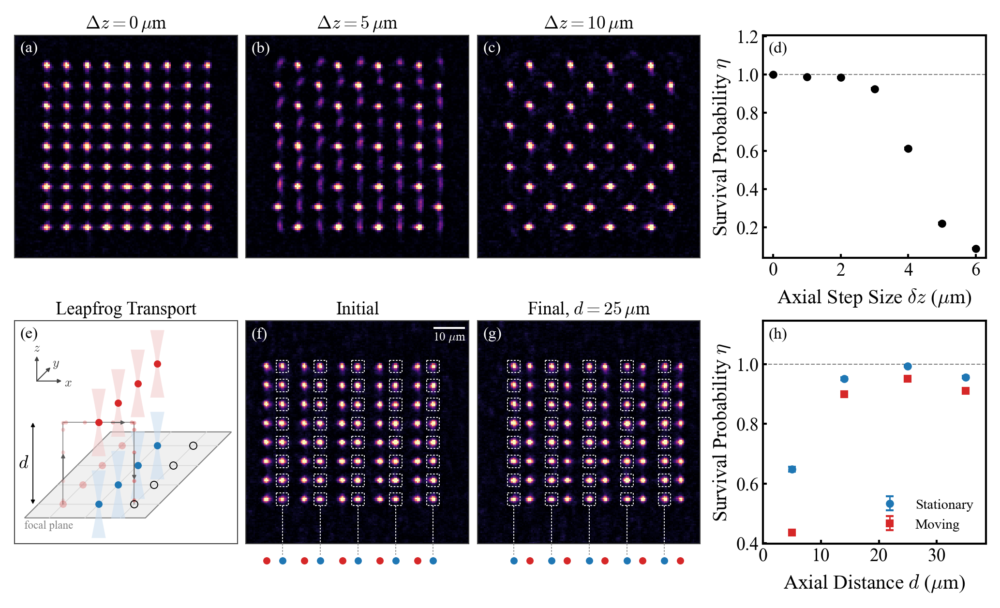

In [37]:
make_figure(img_defoc_0, img_defoc_5, img_defoc_10,
            dz_step_scan, survival_probabilities_axialstep,
            survival_probabilities_err_axialstep,
            img_leapfrog_0, img_leapfrog_1,
            dz_leapfrog_scan,
            survival_probabilities_leapfrog_static,
            survival_probabilities_err_leapfrog_static,
            survival_probabilities_leapfrog_moving,
            survival_probabilities_err_leapfrog_moving,
            out="fig_3d_transport.pdf")